In [27]:
from qiskit import QuantumCircuit
import numpy as np
from scipy.optimize import minimize
from qiskit.quantum_info import DensityMatrix, partial_trace, entropy, Statevector, Kraus, entanglement_of_formation,Operator 
import matplotlib.pyplot as plt


First we consider the same channel as in ``intro_to_correlations.ipynb`` 

In [28]:
# get U1:
qc = QuantumCircuit(2)
qc.x(1)  
qc.h(0)
qc.cx(0, 1)
U1 = Operator(qc)

#get U2
qc2 = QuantumCircuit(2)
qc2.h(0)
qc2.cx(0,1)
U2 = Operator(qc2)

def make_channel(U,p):
    U1,U2 = U
    p0 = p
    p1 = 1-p0
    kruas_ops = [np.sqrt(p0)*U1.data, np.sqrt(p1)*U2.data]
    channel = Kraus(kruas_ops)
    return channel

Quantum discord(QD) is defined as
$$D^\leftarrow = \inf_{\Pi_i}[\mathcal{I}(\rho_{AB}) − \mathcal{J}^\leftarrow(\rho_{AB})].$$
Mutual information ($\mathcal{I}$) is defined as
$$\mathcal{I}(\rho_{AB}) = S(\rho_A)+S(\rho_B)-S(\rho_{AB})$$
where $S(\rho)$ is the von Neumann entropy of the generic state $\rho$. The one way classical correlation is given by
$$\mathcal{J} = S(\rho_A)-\mathcal{H}_{\hat \Pi_i}(A|B)$$
where $\mathcal{H}$ is the quantum conditional entropy associated with the the post measurement density matrix $\rho_{A|B}^i = Tr [\hat \Pi_i \rho_{AB}]/ p_i$\
Subbing these into our expression for $D^{\leftarrow}$ yields
$$ D^\leftarrow = \inf_{\Pi_i}[S(\rho_A)+S(\rho_B)-S(\rho_{AB}) − S(\rho_A)+\mathcal{H}_{\hat \Pi_i}(A|B)] $$
$$ =  S(\rho_B)-S(\rho_{AB}) +  \inf_{\Pi_i}\mathcal{H}_{\hat \Pi_i}(A|B) $$
$$\implies  D^\leftarrow = S(\rho_B)-S(\rho_{AB})+ \inf_{\Pi_i} \sum_i p_iS(\rho_{A|i})$$


In [ ]:
def conditional_entropy(params, rho):
    theta, phi = params
    #basis of spin operators along unit vector n
    basis = np.array([
        [np.cos(theta/2), np.exp(1j * phi)*np.sin(theta/2)],
        [np.sin(theta/2), -np.exp(1j * phi)*np.cos(theta/2)]])

    total =0 
    for b in basis:
        P = np.outer(b,b.conj()) #projection measurement
        M = np.kron(P,np.eye(2)) #hermitian, acts on qubit B (q1)
        post = DensityMatrix(M@rho.data@M)
        p = np.real(np.trace(post.data)) #prob of outcome i 
        if p>1e-12:
            #state of subsystem A:
            rho_A_i = partial_trace(DensityMatrix(post.data/p),[1])
            total += p * entropy(rho_A_i, base=2)
        
    return total   

def QD(rho):

    rho = DensityMatrix(rho)
    rho_A = partial_trace(rho, [1]) #Tr_B[]
    rho_B = partial_trace(rho,[0]) # Tr_A[]

    #entropy
    S_A = entropy(rho_A, base=2)
    S_B = entropy(rho_B, base=2)
    S_AB = entropy(rho, base=2)
    mutual_info = S_A + S_B - S_AB

    #thetas = np.linspace(0,np.pi,100)
    #phis = np.linspace(0,2*np.pi,200)

    #best = min(conditional_entropy([t,p], rho) for t in thetas for p in phis)
    thetas = np.linspace(0, np.pi, 6)
    phis = np.linspace(0, 2 * np.pi, 6, endpoint=False)

    best = min(
    minimize(conditional_entropy, x0=[t, p], args=(rho,),
              method="Nelder-Mead").fun
    for t in thetas
    for p in phis
    )
    J = S_A -best 

    return mutual_info-J


In [ ]:
# recreating fig 1(b) from  "Predominance of entanglement of formation over quantum discord under quantum channels" - Steve Campbell
lambdas = np.linspace(0,1,10)
# Bell state (|00> + |11>)/sqrt(2)
bell = DensityMatrix(Statevector(np.array([1, 0, 0, 1]) / np.sqrt(2)))
QDs_p = []
EoFs_p = []
for lam in lambdas:
    K0 = np.array([[1, 0], [0, np.sqrt(1 - lam)]])
    K1 = np.array([[0, 0], [0, np.sqrt(lam)]])
    phase_damping = Kraus([K0, K1])
    rho_out = bell.evolve(phase_damping, qargs=[1]) 
    QDs_p.append(QD(rho_out))
    EoFs_p.append(entanglement_of_formation(rho_out))

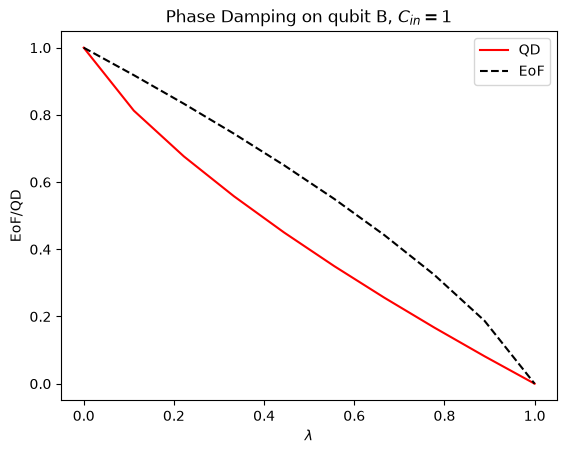

In [40]:
plt.plot(lambdas,QDs_p, label="QD", color = "r")
plt.plot(lambdas, EoFs_p, label = "EoF",linestyle = "--", color = "black")
plt.xlabel("$\\lambda$"); plt.ylabel("EoF/QD"); 
plt.title("Phase Damping on qubit B, $C_{in} = 1$"); plt.legend()
plt.show()

In [34]:
# try for a range of p0 values
p0 = np.linspace(0,1,100)
p1 = 1-p0
QDs = []
EoFs = []
rho0 = DensityMatrix.from_label('00')

for p in p0:
    channel = make_channel([U1,U2],p)
    rho_final = rho0.evolve(channel)
    QDs.append(QD(rho_final))
    EoFs.append(entanglement_of_formation(rho_final))



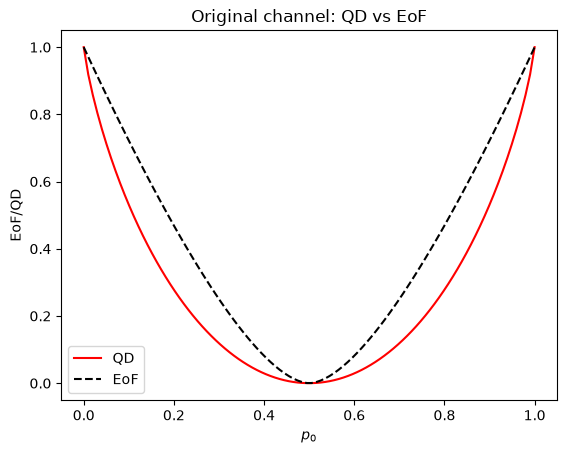

In [36]:
plt.plot(p0,QDs, label="QD", color = "r")
plt.plot(p0, EoFs, label = "EoF",linestyle = "--", color = "black")
plt.xlabel("$p_0$"); plt.ylabel("EoF/QD"); plt.title("Original channel: QD vs EoF")
plt.legend()
plt.show()

Adding an unbalanced branch to original channel: We want

$$U_1\ket{00}=\frac{1}{\sqrt{2}}(\ket{01}+\ket{10})$$
$$ U_2\ket{00}=\cos{\gamma}\ket{00}+\sin{\gamma}\ket{11}$$

In [57]:
def build_unitaries_sin(gamma):
    # U1: |00> -> (|01> + |10>)/sqrt2  (unchanged)
    qc1 = QuantumCircuit(2)
    qc1.x(1)
    qc1.h(0)
    qc1.cx(0, 1)

    # U2: |00> -> cos(gamma)|00> + sin(gamma)|11>
    qc2 = QuantumCircuit(2)
    qc2.ry(2 * gamma, 0)
    qc2.cx(0, 1)

    return Operator(qc1), Operator(qc2)


p0 = np.linspace(0,1,50)
p1 = 1-p0
QDs1 = []
EoFs1 = []
rho0 = DensityMatrix.from_label('00')

for p in p0:
    channel = make_channel(build_unitaries_sin(np.pi / 6), p)
    rho_final = rho0.evolve(channel)
    QDs1.append(QD(rho_final))
    EoFs1.append(entanglement_of_formation(rho_final))

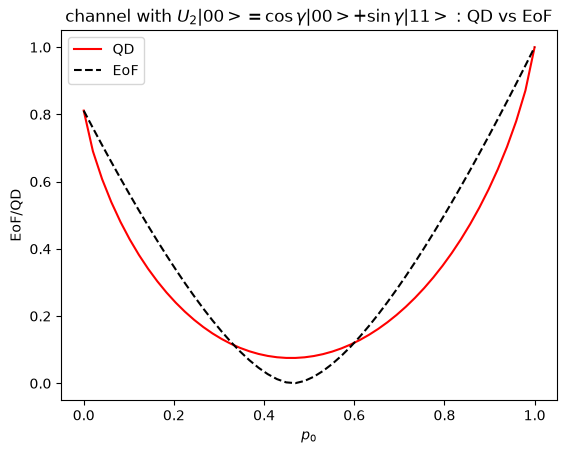

In [58]:
plt.plot(p0,QDs1, label="QD", color = "r")
plt.plot(p0, EoFs1, label = "EoF",linestyle = "--", color = "black")
plt.xlabel("$p_0$"); plt.ylabel("EoF/QD"); plt.title("channel with $U_2|00>=\\cos{\\gamma}|00>+\\sin{\\gamma}|11>$ : QD vs EoF")
plt.legend()
plt.show()

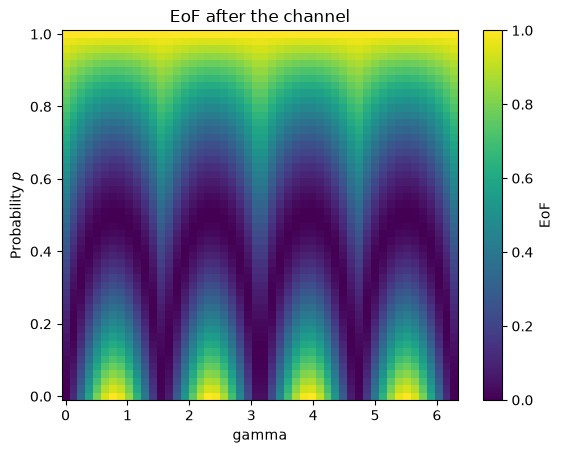

In [61]:
p_values = np.linspace(0, 1, 50)
gammas = np.linspace(0, 2 * np.pi, 50)
eof_grid = np.zeros((len(p_values), len(gammas)))
rho0 = DensityMatrix.from_label('00')
for i, p in enumerate(p_values):

    for j, gamma in enumerate(gammas):
        channel = make_channel(build_unitaries_sin(gamma), p)
        rho_final = rho0.evolve(channel)
        eof_grid[i, j] = entanglement_of_formation(rho_final)

plt.pcolormesh(
    gammas, p_values, eof_grid,
    shading="auto", vmin=0, vmax=1
)
plt.xlabel(r"gamma")
plt.ylabel(r"Probability $p$")
plt.title("EoF after the channel")
plt.colorbar(label="EoF")
plt.show()

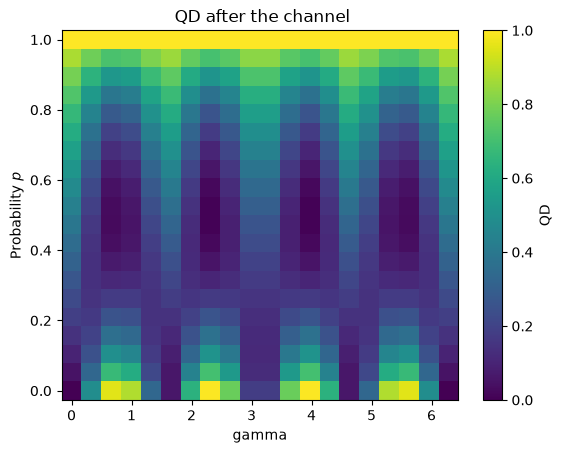

In [63]:
p_values = np.linspace(0, 1, 20)
gammas = np.linspace(0, 2 * np.pi, 20)
qd_grid = np.zeros((len(p_values), len(gammas)))
rho0 = DensityMatrix.from_label('00')
for i, p in enumerate(p_values):

    for j, gamma in enumerate(gammas):
        channel = make_channel(build_unitaries_sin(gamma), p)
        rho_final = rho0.evolve(channel)
        qd_grid[i, j] = QD(rho_final)

plt.pcolormesh(
    gammas, p_values, qd_grid,
    shading="auto", vmin=0, vmax=1
)
plt.xlabel(r"gamma")
plt.ylabel(r"Probability $p$")
plt.title(" QD after the channel")
plt.colorbar(label="QD")
plt.show()